# Final Model Evaluation and Selection

This notebook provides the final comparison of three forecasting approaches:

1. Seasonal Naive baseline
2. Ridge Regression
3. Random Forest

The models are evaluated using an expanding-window, time-aware approach, where past data are used to predict future years. Model performance is compared mainly using Mean Absolute Error (MAE), with RMSE and R-squared (R²) reported as additional measures.

The development backtests cover 2007–2017, while 2018 is used as the final chronological evaluation period. As 2018 was viewed during earlier model-development work, it is not treated as a completely unseen external hold-out.

The purpose of this notebook is to compare the final model performance and support the selection of the most suitable model for this project.

In [58]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42

In [59]:
PROJECT_DIR = Path(".")

DATA_DIR = PROJECT_DIR

RESULTS_DIR = PROJECT_DIR / "results_final"
FIGURES_DIR = PROJECT_DIR / "figures_final"

RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

In [60]:
# adjust this file path as required depending on the local directory structure
POSSIBLE_PATHS = [
    Path("/content/london_housing_model_extended.csv"),
    Path("/mnt/data/london_housing_model_extended.csv"),
    Path("/london_housing_model_extended.csv")
]

DATA_PATH = next(
    (path for path in POSSIBLE_PATHS if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "london_housing_model_extended.csv was not found. "
        "Run Notebook 03 and export/upload the file first."
    )

df = pd.read_csv(DATA_PATH)

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df = (
    df.sort_values(["date", "area"])
      .reset_index(drop=True)
)

display(df.head())

,date,area,average_price,year,quarter,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_12,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m_lag_1,post_2008
0,2002-02-01,barking and dagenham,100229,2002,1,14,0.866,0.500,"98,713.000","95,918.000","90,462.000","83,266.000","97,114.333","94,666.500","90,028.167","5,460.863",2.069,5.481,19.880,216.000,282.000,238.000,248.333,267.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
1,2002-02-01,barnet,202713,2002,1,14,0.866,0.500,"203,249.000","198,610.000","187,691.000","178,108.000","200,883.667","195,936.000","187,877.833","9,465.678",1.224,4.595,15.828,501.000,581.000,388.000,516.333,571.167,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
2,2002-02-01,bexley,124611,2002,1,14,0.866,0.500,"124,283.000","123,381.000","119,312.000","111,439.000","123,366.000","122,091.667","117,617.833","5,006.182",1.510,1.954,11.771,319.000,540.000,331.000,441.667,435.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
3,2002-02-01,brent,171147,2002,1,14,0.866,0.500,"168,671.000","163,992.000","160,832.000","150,110.000","166,165.333","164,464.000","158,984.417","6,345.480",1.711,2.650,13.732,315.000,430.000,297.000,362.000,394.500,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
4,2002-02-01,bromley,172833,2002,1,14,0.866,0.500,"173,150.000","170,870.000","164,849.000","154,097.000","172,201.000","169,790.167","163,759.750","6,960.504",0.329,1.731,12.717,445.000,681.000,410.000,564.333,630.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0


In [61]:
if df.duplicated(["area", "date"]).any():
    raise ValueError(
        "Duplicate borough-month observations detected."
    )

In [62]:
numeric_features = [
    # Time and seasonality
    "time_index",
    "month_sin",
    "month_cos",

    # Historical house prices
    "price_lag_1",
    "price_lag_3",
    "price_lag_6",
    "price_lag_12",

    # Historical price summaries
    "price_rolling_mean_3",
    "price_rolling_mean_6",
    "price_rolling_mean_12",
    "price_rolling_std_12",

    # Historical price growth
    "price_mom_growth_lag_1",
    "price_3m_growth_lag_1",
    "price_yoy_growth_lag_1",

    # Transaction activity
    "houses_sold_lag_1",
    "houses_sold_lag_3",
    "houses_sold_lag_12",
    "houses_sold_rolling_mean_3",
    "houses_sold_rolling_mean_12",

    # Macroeconomic variables
    "cpi_lag_1",
    "cpi_lag_3",
    "cpi_lag_12",

    "bank_rate_lag_1",
    "bank_rate_lag_3",
    "bank_rate_lag_12",
    "bank_rate_change_1m_lag_1"
]

categorical_features = [
    "area"
]

all_features = (
    numeric_features
    + categorical_features
)

target = "average_price"

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))
print("Total predictors:", len(all_features))

Number of numeric features: 26
Number of categorical features: 1
Total predictors: 27


In [63]:
required_columns = list(
    dict.fromkeys(
        [
            "date",
            "year",
            "area",
            target,
            "price_lag_12"
        ]
        + all_features
    )
)

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )

In [64]:
model_columns = list(
    dict.fromkeys(
        [
            "date",
            "year",
            "area",
            target,
            "price_lag_12"
        ]
        + all_features
    )
)

model_df = (
    df[model_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values(["date", "area"])
    .reset_index(drop=True)
)

In [65]:
forbidden_predictors = [
    "average_price",
    "real_price_2015",
    "price_mom_growth_pct",
    "price_3m_growth_pct",
    "price_yoy_growth_pct",

    "houses_sold",

    "cpi_index_2015_100",
    "bank_rate_monthly_avg"
]

leakage_variables = [
    feature
    for feature in all_features
    if feature in forbidden_predictors
]

print(
    "Potential contemporaneous leakage variables:",
    leakage_variables
)

if leakage_variables:
    raise ValueError(
        f"Potential leakage detected: {leakage_variables}"
    )
else:
    print("Leakage check passed.")

Potential contemporaneous leakage variables: []
Leakage check passed.


### Forecasting design and leakage prevention

All target-derived predictors are lagged or calculated using observations preceding the target month.

Contemporaneous average house price, transaction volume, CPI and Bank Rate values are not used directly as predictors.

The evaluation is organised by calendar year using an expanding training window. For each development test year, all earlier observations are used for training and the subsequent year is used for testing.

Because monthly lagged variables are available, this represents a rolling one-step-ahead monthly forecasting framework evaluated across each test year, rather than forecasting all twelve months simultaneously at the beginning of the year.

The latest complete year is excluded from model development and retained as the final hold-out.

In [66]:
year_summary = (
    model_df
    .groupby("year")
    .agg(
        rows=(target, "size"),
        areas=("area", "nunique"),
        months=(
            "date",
            lambda x: x.dt.to_period("M").nunique()
        )
    )
)

display(year_summary)

complete_years = (
    year_summary.loc[
        year_summary["months"].eq(12)
    ]
    .index
    .tolist()
)

,rows,areas,months
year,,,
2002,363,33,11
2003,396,33,12
2004,396,33,12
2005,396,33,12
2006,396,33,12
2007,396,33,12
2008,396,33,12
2009,396,33,12
2010,387,33,12


In [67]:
MINIMUM_TRAINING_YEARS = 5

first_model_year = int(model_df["year"].min())

candidate_test_years = [
    year
    for year in complete_years
    if year >= first_model_year + MINIMUM_TRAINING_YEARS
]

if len(candidate_test_years) < 2:
    raise ValueError(
        "Insufficient complete years for development "
        "and final hold-out."
    )

final_holdout_year = max(candidate_test_years)

development_years = [
    year
    for year in candidate_test_years
    if year < final_holdout_year
]

In [68]:
def calculate_regression_metrics(
    y_true,
    y_pred
):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r_squared = r2_score(
        y_true,
        y_pred
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R_squared": r_squared
    }

In [ ]:
ridge_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median" #Median is more robust against extreme values
                    )
                ),
                (
                    "scaler",
                    StandardScaler() 
                    #Standardising scales ensures predictors measured on different scales are treated fairly
                )
            ]),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ), 
            categorical_features
        )
    ]
)

In [70]:
ridge_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            ridge_preprocessor
        ),
        (
            "model",
            Ridge(
                alpha=10.0
            )
        )
    ]
)

ridge_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['time_index', 'month_sin',
                                                   'month_cos', 'price_lag_1',
                                                   'price_lag_3', 'price_lag_6',
                                                   'price_lag_12',
                                                   'price_rolling_mean_3',
                                                   'price_rolling_mean_6',
                                                   'price_rolling_mean_12',
                                                   'price_rolling_std_...
                                                   'price_yoy_growth_lag_1',
                                                   'houses_sold_lag_1',
                                                   'houses_sold_lag_3',
                                                   'houses_sold_lag_12',
                                                   'houses_sold_rolling_mean_3',
                                                   'houses_sold_rolling_mean_12',
                                                   'cpi_lag_1', 'cpi_lag_3',
                                                   'cpi_lag_12',
                                                   'bank_rate_lag_1',
                                                   'bank_rate_lag_3',
                                                   'bank_rate_lag_12',
                                                   'bank_rate_change_1m_lag_1']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['area'])])),
                ('model', Ridge(alpha=10.0))])

In [ ]:
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(
                strategy="median" #Median is more robust against extreme values
            ),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),  
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

In [ ]:
rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,  
                max_depth=15,
                min_samples_split=5,
                min_samples_leaf=3, 
                max_features="sqrt",
                bootstrap=True,
                random_state=RANDOM_STATE,
                n_jobs=-1  
            )
        )
    ]
)

rf_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  SimpleImputer(strategy='median'),
                                                  ['time_index', 'month_sin',
                                                   'month_cos', 'price_lag_1',
                                                   'price_lag_3', 'price_lag_6',
                                                   'price_lag_12',
                                                   'price_rolling_mean_3',
                                                   'price_rolling_mean_6',
                                                   'price_rolling_mean_12',
                                                   'price_rolling_std_12',
                                                   'price_mom_growth_lag_1',
                                                   'price_3m_...
                                                   'cpi_lag_1', 'cpi_lag_3',
                                                   'cpi_lag_12',
                                                   'bank_rate_lag_1',
                                                   'bank_rate_lag_3',
                                                   'bank_rate_lag_12',
                                                   'bank_rate_change_1m_lag_1']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['area'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, max_features='sqrt',
                                       min_samples_leaf=3, min_samples_split=5,
                                       n_estimators=300, n_jobs=-1,
                                       random_state=42))])

In [73]:
def run_final_backtest(
    data,
    test_years,
    features,
    target_column,
    ridge_model,
    rf_model
):
    yearly_records = []
    prediction_frames = []

    for test_year in test_years:

        print(
            f"\nProcessing test year: {test_year}"
        )

        train_df = (
            data[
                data["year"] < test_year
            ]
            .copy()
        )

        test_df = (
            data[
                data["year"] == test_year
            ]
            .copy()
        )

        if train_df.empty or test_df.empty:
            print(
                f"Skipping {test_year}"
            )
            continue

        X_train = train_df[features]
        y_train = train_df[target_column]

        X_test = test_df[features]
        y_test = test_df[target_column]

        # Seasonal naive baseline

        baseline_predictions = (
            test_df["price_lag_12"]
            .to_numpy()
        )

        # Ridge Regression

        ridge_year_model = clone(
            ridge_model
        )

        ridge_year_model.fit(
            X_train,
            y_train
        )

        ridge_predictions = (
            ridge_year_model.predict(
                X_test
            )
        )

        # Random Forest

        rf_year_model = clone(
            rf_model
        )

        rf_year_model.fit(
            X_train,
            y_train
        )

        rf_predictions = (
            rf_year_model.predict(
                X_test
            )
        )

        predictions = {
            "Seasonal Naive": baseline_predictions,
            "Ridge Regression": ridge_predictions,
            "Random Forest": rf_predictions
        }

        baseline_mae = mean_absolute_error(
            y_test,
            baseline_predictions
        )

        for model_name, prediction in predictions.items():

            metrics = calculate_regression_metrics(
                y_test,
                prediction
            )

            improvement = (
                (
                    baseline_mae
                    - metrics["MAE"]
                )
                / baseline_mae
            ) * 100

            yearly_records.append({
                "test_year": test_year,
                "model": model_name,

                "training_start":
                    train_df["date"].min(),

                "training_end":
                    train_df["date"].max(),

                "testing_start":
                    test_df["date"].min(),

                "testing_end":
                    test_df["date"].max(),

                "training_rows":
                    len(train_df),

                "testing_rows":
                    len(test_df),

                **metrics,

                "MAE_improvement_vs_baseline_pct":
                    improvement
            })

            prediction_frame = (
                test_df[
                    [
                        "date",
                        "year",
                        "area",
                        target_column
                    ]
                ]
                .copy()
            )

            prediction_frame = (
                prediction_frame.rename(
                    columns={
                        target_column:
                            "actual_price"
                    }
                )
            )

            prediction_frame["model"] = (
                model_name
            )

            prediction_frame["prediction"] = (
                prediction
            )

            prediction_frame["error"] = (
                prediction_frame[
                    "actual_price"
                ]
                - prediction_frame[
                    "prediction"
                ]
            )

            prediction_frame[
                "absolute_error"
            ] = (
                prediction_frame[
                    "error"
                ].abs()
            )

            prediction_frames.append(
                prediction_frame
            )

        print(
            f"Completed {test_year}"
        )

    yearly_results = pd.DataFrame(
        yearly_records
    )

    all_predictions = pd.concat(
        prediction_frames,
        ignore_index=True
    )

    return (
        yearly_results,
        all_predictions
    )

In [74]:
development_results, development_predictions = (
    run_final_backtest(
        data=model_df,
        test_years=development_years,
        features=all_features,
        target_column=target,
        ridge_model=ridge_pipeline,
        rf_model=rf_pipeline
    )
)

display(
    development_results.head(12)
)


Processing test year: 2007
Completed 2007

Processing test year: 2008
Completed 2008

Processing test year: 2009
Completed 2009

Processing test year: 2010
Completed 2010

Processing test year: 2011
Completed 2011

Processing test year: 2012
Completed 2012

Processing test year: 2013
Completed 2013

Processing test year: 2014
Completed 2014

Processing test year: 2015
Completed 2015

Processing test year: 2016
Completed 2016

Processing test year: 2017
Completed 2017


,test_year,model,training_start,training_end,testing_start,testing_end,training_rows,testing_rows,MAE,RMSE,R_squared,MAE_improvement_vs_baseline_pct
0,2007,Seasonal Naive,2002-02-01,2006-12-01,2007-01-01,2007-12-01,1947,396,"42,936.980","51,995.545",0.784,0.000
1,2007,Ridge Regression,2002-02-01,2006-12-01,2007-01-01,2007-12-01,1947,396,"4,883.533","9,106.366",0.993,88.626
2,2007,Random Forest,2002-02-01,2006-12-01,2007-01-01,2007-12-01,1947,396,"11,605.025","30,869.620",0.924,72.972
3,2008,Seasonal Naive,2002-02-01,2007-12-01,2008-01-01,2008-12-01,2343,396,"24,785.278","31,571.873",0.929,0.000
4,2008,Ridge Regression,2002-02-01,2007-12-01,2008-01-01,2008-12-01,2343,396,"9,331.465","13,232.732",0.987,62.351
5,2008,Random Forest,2002-02-01,2007-12-01,2008-01-01,2008-12-01,2343,396,"18,331.212","25,180.457",0.955,26.040
6,2009,Seasonal Naive,2002-02-01,2008-12-01,2009-01-01,2009-12-01,2739,396,"34,971.760","42,866.659",0.852,0.000
7,2009,Ridge Regression,2002-02-01,2008-12-01,2009-01-01,2009-12-01,2739,396,"11,574.919","14,424.416",0.983,66.902
8,2009,Random Forest,2002-02-01,2008-12-01,2009-01-01,2009-12-01,2739,396,"9,928.838","15,442.765",0.981,71.609
9,2010,Seasonal Naive,2002-02-01,2009-12-01,2010-01-01,2010-12-01,3135,387,"32,882.473","43,185.978",0.897,0.000


In [75]:
mae_table = (
    development_results
    .pivot(
        index="test_year",
        columns="model",
        values="MAE"
    )
)

display(
    mae_table.style.format(
        "£{:,.0f}"
    )
)

model,Random Forest,Ridge Regression,Seasonal Naive
test_year,,,
2007,"£11,605","£4,884","£42,937"
2008,"£18,331","£9,331","£24,785"
2009,"£9,929","£11,575","£34,972"
2010,"£8,296","£4,990","£32,882"
2011,"£6,887","£4,019","£11,800"
2012,"£7,923","£4,395","£17,668"
2013,"£9,364","£4,737","£30,564"
2014,"£13,919","£5,401","£62,252"
2015,"£9,820","£6,571","£39,566"


In [76]:
consistency_summary = (
    development_results
    .groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        median_MAE=("MAE", "median"),
        MAE_std=("MAE", "std"),
        minimum_MAE=("MAE", "min"),
        maximum_MAE=("MAE", "max")
    )
    .reset_index()
)

consistency_summary["MAE_range"] = (
    consistency_summary["maximum_MAE"]
    - consistency_summary["minimum_MAE"]
)

consistency_summary = (
    consistency_summary
    .sort_values("mean_MAE")
    .reset_index(drop=True)
)

display(
    consistency_summary.style.format({
        "mean_MAE": "£{:,.0f}",
        "median_MAE": "£{:,.0f}",
        "MAE_std": "£{:,.0f}",
        "minimum_MAE": "£{:,.0f}",
        "maximum_MAE": "£{:,.0f}",
        "MAE_range": "£{:,.0f}"
    })
)

,model,mean_MAE,median_MAE,MAE_std,minimum_MAE,maximum_MAE,MAE_range
0,Ridge Regression,"£6,417","£5,401","£2,344","£4,019","£11,575","£7,556"
1,Random Forest,"£10,773","£9,929","£3,183","£6,887","£18,331","£11,444"
2,Seasonal Naive,"£32,628","£32,882","£14,317","£11,800","£62,252","£50,452"


In [77]:
most_accurate_model = (
    consistency_summary
    .sort_values("mean_MAE")
    .iloc[0]["model"]
)

most_consistent_model = (
    consistency_summary
    .sort_values("MAE_range")
    .iloc[0]["model"]
)

Expanding-Window Forecast MAE by Test Year

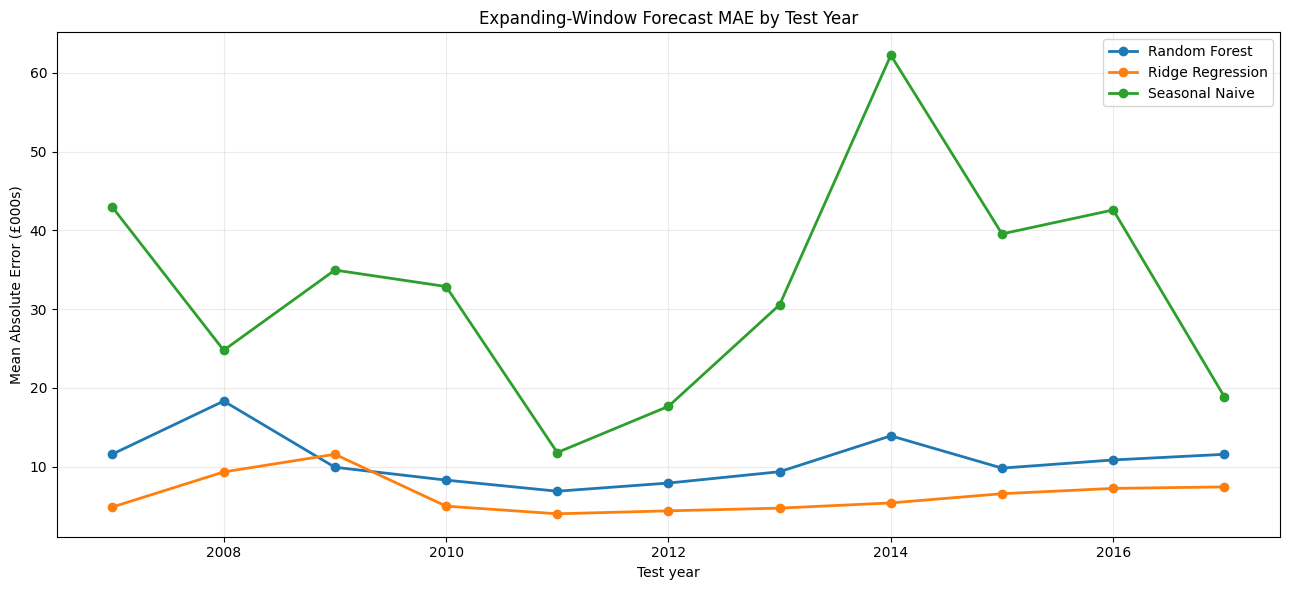

In [78]:
plt.figure(figsize=(13, 6))

for model_name, group in (
    development_results.groupby("model")
):

    group = group.sort_values(
        "test_year"
    )

    plt.plot(
        group["test_year"],
        group["MAE"] / 1_000,
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title(
    "Expanding-Window Forecast MAE by Test Year"
)

plt.xlabel(
    "Test year"
)

plt.ylabel(
    "Mean Absolute Error (£000s)"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_annual_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
improvement_table = (
    development_results
    .pivot(
        index="test_year",
        columns="model",
        values="MAE_improvement_vs_baseline_pct"
    )
    .drop(
        columns=["Seasonal Naive"],
        errors="ignore"
    )
)

display(
    improvement_table.style.format(
        "{:.2f}%"
    )
)

model,Random Forest,Ridge Regression
test_year,,
2007,72.97%,88.63%
2008,26.04%,62.35%
2009,71.61%,66.90%
2010,74.77%,84.82%
2011,41.64%,65.95%
2012,55.16%,75.13%
2013,69.36%,84.50%
2014,77.64%,91.32%
2015,75.18%,83.39%


MAE Improvement Relative to Seasonal Naive Baseline

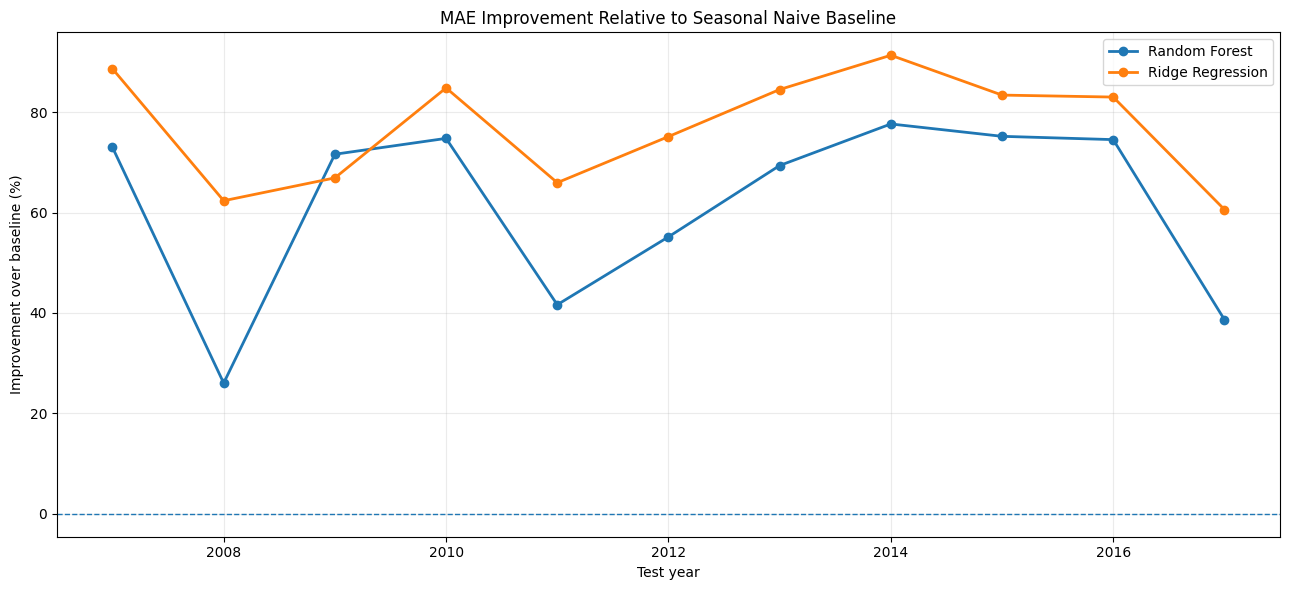

In [80]:
plt.figure(figsize=(13, 6))

for model_name in improvement_table.columns:

    plt.plot(
        improvement_table.index,
        improvement_table[model_name],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "MAE Improvement Relative to Seasonal Naive Baseline"
)

plt.xlabel(
    "Test year"
)

plt.ylabel(
    "Improvement over baseline (%)"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_improvement_over_baseline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
overall_development_summary = (
    development_results
    .groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        median_MAE=("MAE", "median"),
        mean_RMSE=("RMSE", "mean"),
        mean_R_squared=("R_squared", "mean"),
        mean_improvement_pct=(
            "MAE_improvement_vs_baseline_pct",
            "mean"
        )
    )
    .reset_index()
    .sort_values("mean_MAE")
)

display(
    overall_development_summary.style.format({
        "mean_MAE": "£{:,.0f}",
        "median_MAE": "£{:,.0f}",
        "mean_RMSE": "£{:,.0f}",
        "mean_R_squared": "{:.3f}",
        "mean_improvement_pct": "{:.2f}%"
    })
)

,model,mean_MAE,median_MAE,mean_RMSE,mean_R_squared,mean_improvement_pct
1,Ridge Regression,"£6,417","£5,401","£10,145",0.995,76.96%
0,Random Forest,"£10,773","£9,929","£22,581",0.976,61.60%
2,Seasonal Naive,"£32,628","£32,882","£40,618",0.923,0.00%


In [82]:
final_train_df = (
    model_df[
        model_df["year"]
        < final_holdout_year
    ]
    .copy()
)

final_test_df = (
    model_df[
        model_df["year"]
        == final_holdout_year
    ]
    .copy()
)

In [83]:
X_final_train = (
    final_train_df[
        all_features
    ]
)

y_final_train = (
    final_train_df[
        target
    ]
)

X_final_test = (
    final_test_df[
        all_features
    ]
)

y_final_test = (
    final_test_df[
        target
    ]
)

final_ridge_model = clone(
    ridge_pipeline
)

final_rf_model = clone(
    rf_pipeline
)

final_ridge_model.fit(
    X_final_train,
    y_final_train
)

final_rf_model.fit(
    X_final_train,
    y_final_train
)

ridge_holdout_predictions = (
    final_ridge_model.predict(
        X_final_test
    )
)

rf_holdout_predictions = (
    final_rf_model.predict(
        X_final_test
    )
)

baseline_holdout_predictions = (
    final_test_df[
        "price_lag_12"
    ]
    .to_numpy()
)

In [84]:
final_holdout_records = []

holdout_predictions_dict = {
    "Seasonal Naive":
        baseline_holdout_predictions,

    "Ridge Regression":
        ridge_holdout_predictions,

    "Random Forest":
        rf_holdout_predictions
}

baseline_holdout_mae = (
    mean_absolute_error(
        y_final_test,
        baseline_holdout_predictions
    )
)

for model_name, predictions in (
    holdout_predictions_dict.items()
):

    metrics = (
        calculate_regression_metrics(
            y_final_test,
            predictions
        )
    )

    improvement = (
        (
            baseline_holdout_mae
            - metrics["MAE"]
        )
        / baseline_holdout_mae
    ) * 100

    final_holdout_records.append({
        "model": model_name,
        **metrics,
        "MAE_improvement_vs_baseline_pct":
            improvement
    })

final_holdout_results = (
    pd.DataFrame(
        final_holdout_records
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    final_holdout_results.style.format({
        "MAE": "£{:,.0f}",
        "RMSE": "£{:,.0f}",
        "R_squared": "{:.3f}",
        "MAE_improvement_vs_baseline_pct":
            "{:.2f}%"
    })
)

,model,MAE,RMSE,R_squared,MAE_improvement_vs_baseline_pct
0,Ridge Regression,"£8,131","£14,347",0.995,42.46%
1,Random Forest,"£10,890","£20,013",0.991,22.93%
2,Seasonal Naive,"£14,131","£24,189",0.987,0.00%


In [85]:
final_predictions = (
    final_test_df[
        [
            "date",
            "year",
            "area",
            target
        ]
    ]
    .copy()
)

final_predictions = (
    final_predictions.rename(
        columns={
            target:
                "actual_price"
        }
    )
)

final_predictions[
    "seasonal_naive_prediction"
] = (
    baseline_holdout_predictions
)

final_predictions[
    "ridge_prediction"
] = (
    ridge_holdout_predictions
)

final_predictions[
    "rf_prediction"
] = (
    rf_holdout_predictions
)

final_predictions[
    "ridge_error"
] = (
    final_predictions["actual_price"]
    - final_predictions[
        "ridge_prediction"
    ]
)

final_predictions[
    "rf_error"
] = (
    final_predictions["actual_price"]
    - final_predictions[
        "rf_prediction"
    ]
)

final_predictions[
    "ridge_absolute_error"
] = (
    final_predictions[
        "ridge_error"
    ].abs()
)

final_predictions[
    "rf_absolute_error"
] = (
    final_predictions[
        "rf_error"
    ].abs()
)

display(
    final_predictions.head()
)

,date,year,area,actual_price,seasonal_naive_prediction,ridge_prediction,rf_prediction,ridge_error,rf_error,ridge_absolute_error,rf_absolute_error
6210,2018-01-01,2018,barking and dagenham,291548,"282,441.000","293,663.575","294,625.657","-2,115.575","-3,077.657","2,115.575","3,077.657"
6211,2018-01-01,2018,barnet,531832,"532,924.000","540,856.534","537,211.768","-9,024.534","-5,379.768","9,024.534","5,379.768"
6212,2018-01-01,2018,bexley,342096,"330,066.000","344,420.953","344,093.611","-2,324.953","-1,997.611","2,324.953","1,997.611"
6213,2018-01-01,2018,brent,493882,"472,373.000","497,293.875","492,371.806","-3,411.875","1,510.194","3,411.875","1,510.194"
6214,2018-01-01,2018,bromley,446737,"436,538.000","447,548.397","449,314.852",-811.397,"-2,577.852",811.397,"2,577.852"


In [86]:
monthly_final = (
    final_predictions
    .groupby("date")
    .agg(
        actual_price=(
            "actual_price",
            "mean"
        ),

        seasonal_naive_prediction=(
            "seasonal_naive_prediction",
            "mean"
        ),

        ridge_prediction=(
            "ridge_prediction",
            "mean"
        ),

        rf_prediction=(
            "rf_prediction",
            "mean"
        )
    )
    .reset_index()
)

Actual and Predicted Mean Borough House Prices - 2018

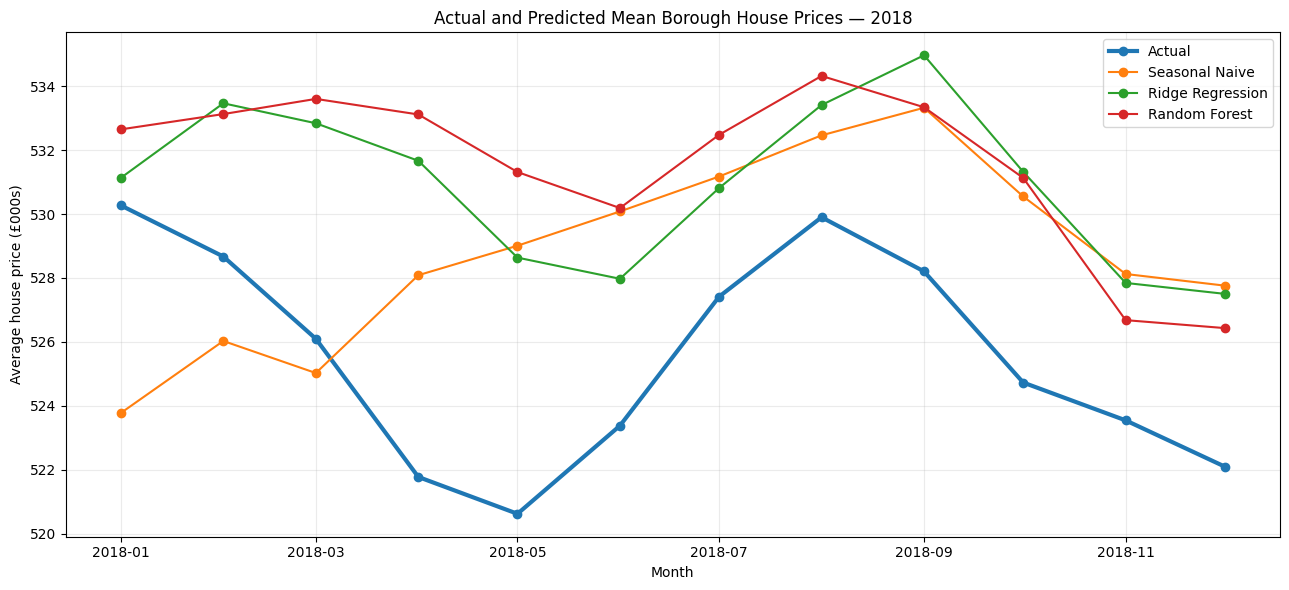

In [87]:
plt.figure(figsize=(13, 6))

plt.plot(
    monthly_final["date"],
    monthly_final["actual_price"] / 1_000,
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    monthly_final["date"],
    monthly_final[
        "seasonal_naive_prediction"
    ] / 1_000,
    marker="o",
    label="Seasonal Naive"
)

plt.plot(
    monthly_final["date"],
    monthly_final[
        "ridge_prediction"
    ] / 1_000,
    marker="o",
    label="Ridge Regression"
)

plt.plot(
    monthly_final["date"],
    monthly_final[
        "rf_prediction"
    ] / 1_000,
    marker="o",
    label="Random Forest"
)

plt.title(
    f"Actual and Predicted Mean Borough House Prices — "
    f"{final_holdout_year}"
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Average house price (£000s)"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_final_holdout_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
bias_summary = pd.DataFrame({
    "model": [
        "Ridge Regression",
        "Random Forest"
    ],

    "mean_error": [
        final_predictions[
            "ridge_error"
        ].mean(),

        final_predictions[
            "rf_error"
        ].mean()
    ]
})

bias_summary["interpretation"] = np.where(
    bias_summary["mean_error"] < 0,
    "Overall overprediction",
    "Overall underprediction"
)

display(
    bias_summary.style.format({
        "mean_error": "£{:,.0f}"
    })
)

,model,mean_error,interpretation
0,Ridge Regression,"£-5,405",Overall overprediction
1,Random Forest,"£-5,972",Overall overprediction


In [89]:
borough_error_summary = (
    final_predictions
    .groupby("area")
    .agg(
        mean_actual_price=(
            "actual_price",
            "mean"
        ),

        ridge_MAE=(
            "ridge_absolute_error",
            "mean"
        ),

        random_forest_MAE=(
            "rf_absolute_error",
            "mean"
        ),

        ridge_bias=(
            "ridge_error",
            "mean"
        ),

        random_forest_bias=(
            "rf_error",
            "mean"
        )
    )
    .reset_index()
)

In [90]:
display(
    borough_error_summary
    .sort_values(
        "ridge_MAE",
        ascending=False
    )
    .head(10)
    .style.format({
        "mean_actual_price": "£{:,.0f}",
        "ridge_MAE": "£{:,.0f}",
        "random_forest_MAE": "£{:,.0f}",
        "ridge_bias": "£{:,.0f}",
        "random_forest_bias": "£{:,.0f}"
    })
)

,area,mean_actual_price,ridge_MAE,random_forest_MAE,ridge_bias,random_forest_bias
18,kensington and chelsea,"£1,363,880","£40,487","£55,186","£-10,067","£53,379"
31,westminster,"£1,020,026","£35,035","£57,022","£-28,554","£-53,152"
5,camden,"£842,410","£19,817","£24,019","£-5,820","£-14,483"
11,hammersmith and fulham,"£725,525","£14,126","£20,567","£-10,785","£-20,567"
17,islington,"£649,824","£11,735","£12,026","£-6,985","£-10,871"
25,richmond upon thames,"£652,666","£9,061","£8,973","£-7,207","£-6,270"
3,brent,"£492,845","£8,352","£9,452","£-4,472","£-3,181"
26,southwark,"£504,235","£8,234","£8,065","£-6,210","£-5,581"
10,hackney,"£544,640","£8,210","£9,464","£-7,416","£-8,452"
28,tower hamlets,"£446,500","£7,783","£12,091","£-6,974","£-11,750"


In [91]:
ridge_price_error_corr = (
    borough_error_summary[
        "mean_actual_price"
    ]
    .corr(
        borough_error_summary[
            "ridge_MAE"
        ]
    )
)

rf_price_error_corr = (
    borough_error_summary[
        "mean_actual_price"
    ]
    .corr(
        borough_error_summary[
            "random_forest_MAE"
        ]
    )
)

print(
    "Correlation between borough price "
    "and Ridge MAE:",
    round(ridge_price_error_corr, 3)
)

print(
    "Correlation between borough price "
    "and Random Forest MAE:",
    round(rf_price_error_corr, 3)
)

Correlation between borough price and Ridge MAE: 0.964
Correlation between borough price and Random Forest MAE: 0.917


In [92]:
borough_error_summary[
    "price_group"
] = pd.qcut(
    borough_error_summary[
        "mean_actual_price"
    ],
    q=3,
    labels=[
        "Lower-price boroughs",
        "Middle-price boroughs",
        "Higher-price boroughs"
    ]
)

display(
    borough_error_summary[
        [
            "area",
            "mean_actual_price",
            "price_group",
            "ridge_MAE",
            "random_forest_MAE"
        ]
    ]
    .sort_values(
        "mean_actual_price"
    )
)

,area,mean_actual_price,price_group,ridge_MAE,random_forest_MAE
0,barking and dagenham,"295,196.667",Lower-price boroughs,"2,428.989","2,383.554"
2,bexley,"342,603.583",Lower-price boroughs,"2,754.495","4,236.671"
23,newham,"359,022.500",Lower-price boroughs,"3,196.666","5,959.512"
14,havering,"370,248.917",Lower-price boroughs,"2,352.787","2,214.102"
6,croydon,"370,298.417",Lower-price boroughs,"3,420.764","5,870.408"
27,sutton,"379,262.583",Lower-price boroughs,"3,553.198","6,517.182"
9,greenwich,"388,344.417",Lower-price boroughs,"4,625.372","8,433.971"
16,hounslow,"396,631.083",Lower-price boroughs,"5,728.302","5,912.930"
8,enfield,"396,631.667",Lower-price boroughs,"3,046.903","4,269.818"
15,hillingdon,"410,266.000",Lower-price boroughs,"3,369.475","6,211.304"


In [93]:
price_group_results = (
    borough_error_summary
    .groupby(
        "price_group",
        observed=True
    )
    .agg(
        mean_borough_price=(
            "mean_actual_price",
            "mean"
        ),

        ridge_MAE=(
            "ridge_MAE",
            "mean"
        ),

        random_forest_MAE=(
            "random_forest_MAE",
            "mean"
        ),

        number_of_boroughs=(
            "area",
            "count"
        )
    )
    .reset_index()
)

display(
    price_group_results.style.format({
        "mean_borough_price": "£{:,.0f}",
        "ridge_MAE": "£{:,.0f}",
        "random_forest_MAE": "£{:,.0f}"
    })
)

,price_group,mean_borough_price,ridge_MAE,random_forest_MAE,number_of_boroughs
0,Lower-price boroughs,"£374,558","£3,513","£5,216",11
1,Middle-price boroughs,"£470,503","£5,588","£7,020",10
2,Higher-price boroughs,"£726,613","£15,060","£20,082",11


Prediction Error by Borough Price Group - 2018

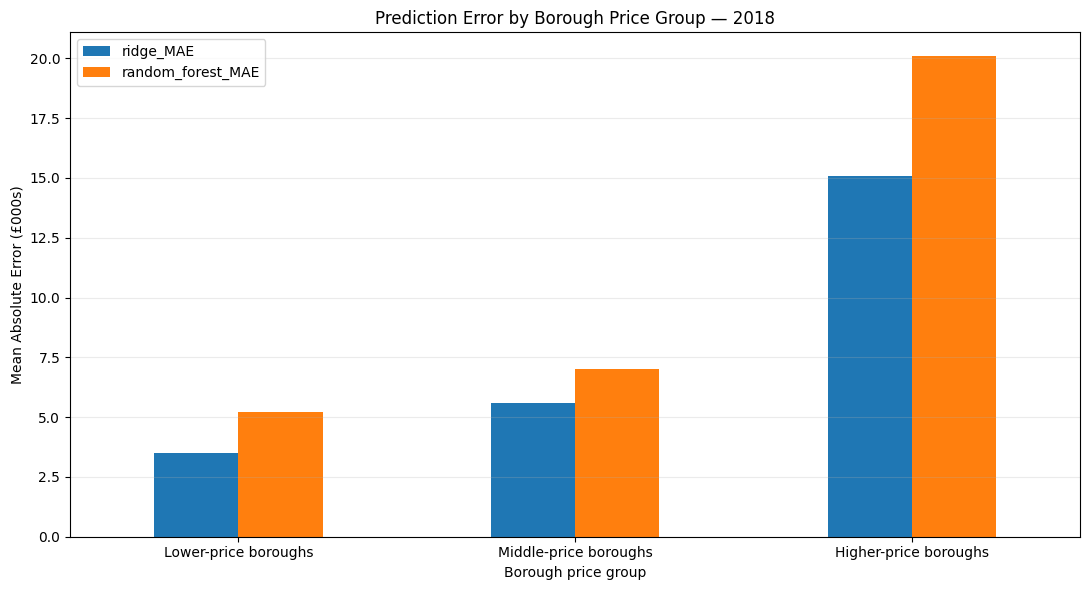

In [94]:
plot_data = (
    price_group_results
    .set_index("price_group")[
        [
            "ridge_MAE",
            "random_forest_MAE"
        ]
    ]
    / 1_000
)

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    f"Prediction Error by Borough Price Group — "
    f"{final_holdout_year}"
)

ax.set_xlabel(
    "Borough price group"
)

ax.set_ylabel(
    "Mean Absolute Error (£000s)"
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_mae_by_borough_price_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##Borough price vs MAE

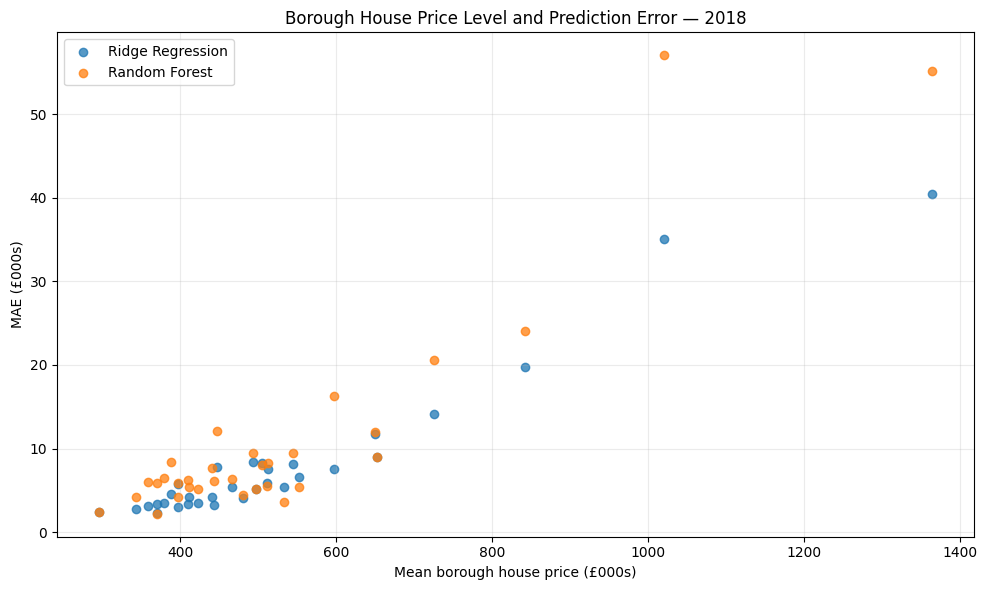

In [95]:
plt.figure(figsize=(10, 6))

plt.scatter(
    borough_error_summary[
        "mean_actual_price"
    ] / 1_000,

    borough_error_summary[
        "ridge_MAE"
    ] / 1_000,

    alpha=0.75,
    label="Ridge Regression"
)

plt.scatter(
    borough_error_summary[
        "mean_actual_price"
    ] / 1_000,

    borough_error_summary[
        "random_forest_MAE"
    ] / 1_000,

    alpha=0.75,
    label="Random Forest"
)

plt.xlabel(
    "Mean borough house price (£000s)"
)

plt.ylabel(
    "MAE (£000s)"
)

plt.title(
    f"Borough House Price Level and Prediction Error — "
    f"{final_holdout_year}"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_borough_price_vs_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

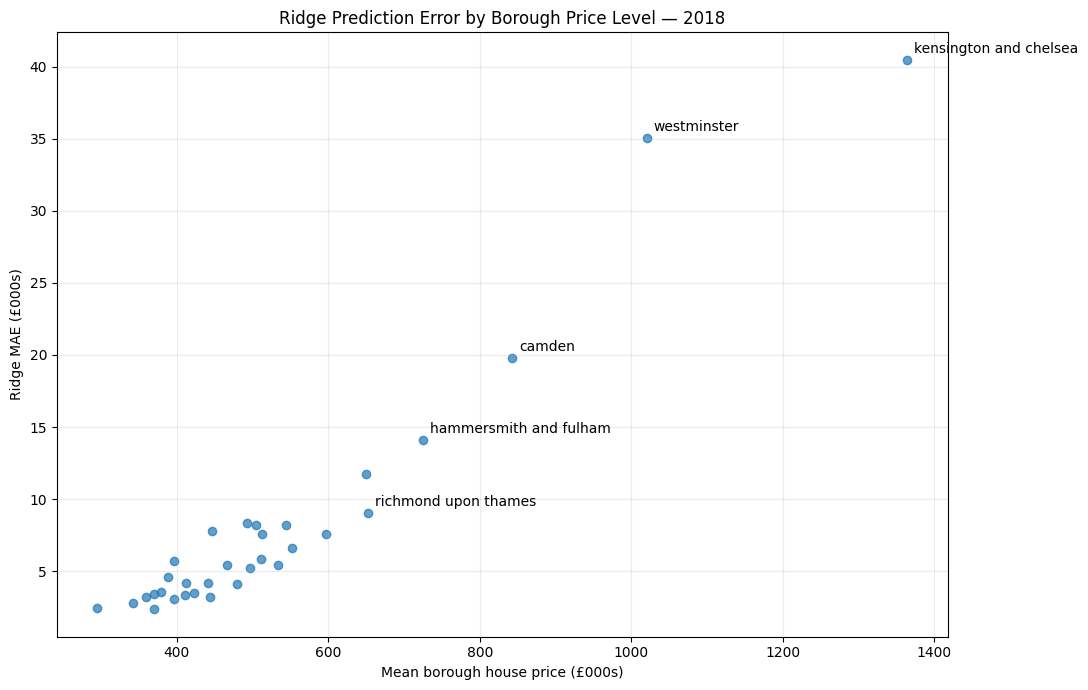

In [96]:
top_expensive = (
    borough_error_summary
    .nlargest(
        5,
        "mean_actual_price"
    )
)

plt.figure(figsize=(11, 7))

plt.scatter(
    borough_error_summary[
        "mean_actual_price"
    ] / 1_000,

    borough_error_summary[
        "ridge_MAE"
    ] / 1_000,

    alpha=0.7
)

for _, row in top_expensive.iterrows():

    plt.annotate(
        row["area"],

        (
            row["mean_actual_price"] / 1_000,
            row["ridge_MAE"] / 1_000
        ),

        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Mean borough house price (£000s)"
)

plt.ylabel(
    "Ridge MAE (£000s)"
)

plt.title(
    f"Ridge Prediction Error by Borough Price Level — "
    f"{final_holdout_year}"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_ridge_borough_error_diagnostic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

prediction error increases with borough house-price level. Both models perform reasonably well for lower-priced boroughs, but errors become much larger for expensive boroughs, with Ridge generally outperforming Random Forest at the highest price levels.

In [97]:
largest_ridge_errors = (
    final_predictions
    .nlargest(
        15,
        "ridge_absolute_error"
    )
    [
        [
            "date",
            "area",
            "actual_price",
            "ridge_prediction",
            "ridge_error",
            "ridge_absolute_error"
        ]
    ]
)

display(
    largest_ridge_errors.style.format({
        "actual_price": "£{:,.0f}",
        "ridge_prediction": "£{:,.0f}",
        "ridge_error": "£{:,.0f}",
        "ridge_absolute_error": "£{:,.0f}"
    })
)

,date,area,actual_price,ridge_prediction,ridge_error,ridge_absolute_error
6228,2018-01-01 00:00:00,kensington and chelsea,"£1,463,378","£1,367,409","£95,969","£95,969"
6593,2018-12-01 00:00:00,westminster,"£965,023","£1,044,792","£-79,769","£79,769"
6324,2018-04-01 00:00:00,kensington and chelsea,"£1,325,081","£1,401,888","£-76,807","£76,807"
6337,2018-04-01 00:00:00,westminster,"£1,003,535","£1,075,078","£-71,543","£71,543"
6452,2018-08-01 00:00:00,kensington and chelsea,"£1,418,032","£1,346,934","£71,098","£71,098"
6260,2018-02-01 00:00:00,kensington and chelsea,"£1,378,878","£1,444,887","£-66,009","£66,009"
6369,2018-05-01 00:00:00,westminster,"£980,480","£1,034,300","£-53,820","£53,820"
6305,2018-03-01 00:00:00,westminster,"£1,060,664","£1,112,784","£-52,120","£52,120"
6401,2018-06-01 00:00:00,westminster,"£968,778","£1,018,637","£-49,859","£49,859"
6356,2018-05-01 00:00:00,kensington and chelsea,"£1,301,729","£1,350,642","£-48,913","£48,913"


In [98]:
final_model_summary = (
    final_holdout_results
    .merge(
        consistency_summary[
            [
                "model",
                "mean_MAE",
                "MAE_std",
                "MAE_range"
            ]
        ],
        on="model",
        how="left"
    )
)

final_model_summary = (
    final_model_summary.rename(
        columns={
            "MAE":
                "holdout_MAE",

            "RMSE":
                "holdout_RMSE",

            "R_squared":
                "holdout_R_squared",

            "mean_MAE":
                "development_mean_MAE",

            "MAE_std":
                "development_MAE_std",

            "MAE_range":
                "development_MAE_range"
        }
    )
)

display(
    final_model_summary.style.format({
        "holdout_MAE": "£{:,.0f}",
        "holdout_RMSE": "£{:,.0f}",
        "holdout_R_squared": "{:.3f}",
        "MAE_improvement_vs_baseline_pct":
            "{:.2f}%",
        "development_mean_MAE":
            "£{:,.0f}",
        "development_MAE_std":
            "£{:,.0f}",
        "development_MAE_range":
            "£{:,.0f}"
    })
)

,model,holdout_MAE,holdout_RMSE,holdout_R_squared,MAE_improvement_vs_baseline_pct,development_mean_MAE,development_MAE_std,development_MAE_range
0,Ridge Regression,"£8,131","£14,347",0.995,42.46%,"£6,417","£2,344","£7,556"
1,Random Forest,"£10,890","£20,013",0.991,22.93%,"£10,773","£3,183","£11,444"
2,Seasonal Naive,"£14,131","£24,189",0.987,0.00%,"£32,628","£14,317","£50,452"


In [99]:
ridge_summary = (
    final_model_summary[
        final_model_summary["model"]
        == "Ridge Regression"
    ]
    .iloc[0]
)

rf_summary = (
    final_model_summary[
        final_model_summary["model"]
        == "Random Forest"
    ]
    .iloc[0]
)

print("FINAL MODEL COMPARISON")
print("-" * 50)

print(
    f"Ridge hold-out MAE: "
    f"£{ridge_summary['holdout_MAE']:,.0f}"
)

print(
    f"Random Forest hold-out MAE: "
    f"£{rf_summary['holdout_MAE']:,.0f}"
)

print()

print(
    f"Ridge development mean MAE: "
    f"£{ridge_summary['development_mean_MAE']:,.0f}"
)

print(
    f"Random Forest development mean MAE: "
    f"£{rf_summary['development_mean_MAE']:,.0f}"
)

print()

print(
    f"Ridge MAE range: "
    f"£{ridge_summary['development_MAE_range']:,.0f}"
)

print(
    f"Random Forest MAE range: "
    f"£{rf_summary['development_MAE_range']:,.0f}"
)

FINAL MODEL COMPARISON
--------------------------------------------------
Ridge hold-out MAE: £8,131
Random Forest hold-out MAE: £10,890

Ridge development mean MAE: £6,417
Random Forest development mean MAE: £10,773

Ridge MAE range: £7,556
Random Forest MAE range: £11,444


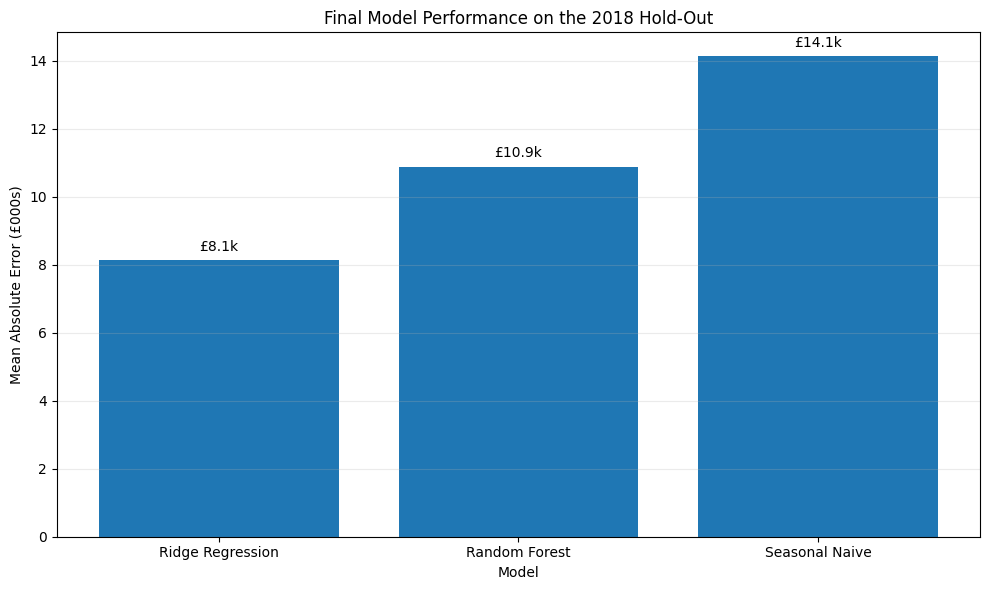

In [100]:
# Final hold-out MAE comparison

final_plot = (
    final_holdout_results
    .sort_values("MAE")
    .copy()
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    final_plot["model"],
    final_plot["MAE"] / 1_000
)

plt.title(
    f"Final Model Performance on the {final_holdout_year} Hold-Out"
)

plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (£000s)")

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, mae in zip(
    bars,
    final_plot["MAE"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"£{mae / 1_000:.1f}k",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "07_final_holdout_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [101]:
report_model_table = (
    final_model_summary[
        [
            "model",
            "development_mean_MAE",
            "development_MAE_std",
            "development_MAE_range",
            "holdout_MAE",
            "holdout_RMSE",
            "holdout_R_squared",
            "MAE_improvement_vs_baseline_pct"
        ]
    ]
    .copy()
)

report_model_table = (
    report_model_table.rename(
        columns={
            "model": "Model",
            "development_mean_MAE": "Development Mean MAE",
            "development_MAE_std": "Development MAE SD",
            "development_MAE_range": "Development MAE Range",
            "holdout_MAE": "2018 Hold-Out MAE",
            "holdout_RMSE": "2018 Hold-Out RMSE",
            "holdout_R_squared": "2018 Hold-Out R²",
            "MAE_improvement_vs_baseline_pct":
                "2018 MAE Improvement vs Baseline (%)"
        }
    )
)

report_model_table = (
    report_model_table
    .sort_values("2018 Hold-Out MAE")
    .reset_index(drop=True)
)

display(
    report_model_table.style.format({
        "Development Mean MAE": "£{:,.0f}",
        "Development MAE SD": "£{:,.0f}",
        "Development MAE Range": "£{:,.0f}",
        "2018 Hold-Out MAE": "£{:,.0f}",
        "2018 Hold-Out RMSE": "£{:,.0f}",
        "2018 Hold-Out R²": "{:.3f}",
        "2018 MAE Improvement vs Baseline (%)": "{:.2f}%"
    })
)

report_model_table.to_csv(
    RESULTS_DIR /
    "07_dissertation_final_model_comparison.csv",
    index=False
)

,Model,Development Mean MAE,Development MAE SD,Development MAE Range,2018 Hold-Out MAE,2018 Hold-Out RMSE,2018 Hold-Out R²,2018 MAE Improvement vs Baseline (%)
0,Ridge Regression,"£6,417","£2,344","£7,556","£8,131","£14,347",0.995,42.46%
1,Random Forest,"£10,773","£3,183","£11,444","£10,890","£20,013",0.991,22.93%
2,Seasonal Naive,"£32,628","£14,317","£50,452","£14,131","£24,189",0.987,0.00%


In [102]:
if (
    ridge_summary[
        "development_mean_MAE"
    ]
    <
    rf_summary[
        "development_mean_MAE"
    ]
):

    print(
        "Ridge Regression has the lower "
        "average development MAE."
    )

else:

    print(
        "Random Forest has the lower "
        "average development MAE."
    )


if (
    ridge_summary[
        "development_MAE_range"
    ]
    <
    rf_summary[
        "development_MAE_range"
    ]
):

    print(
        "Ridge Regression has the smaller "
        "year-to-year MAE range."
    )

else:

    print(
        "Random Forest has the smaller "
        "year-to-year MAE range."
    )

Ridge Regression has the lower average development MAE.
Ridge Regression has the smaller year-to-year MAE range.


In [103]:
development_results.to_csv(
    RESULTS_DIR /
    "07_development_yearly_results.csv",
    index=False
)

consistency_summary.to_csv(
    RESULTS_DIR /
    "07_model_consistency_summary.csv",
    index=False
)

final_holdout_results.to_csv(
    RESULTS_DIR /
    "07_final_holdout_results.csv",
    index=False
)

final_predictions.to_csv(
    RESULTS_DIR /
    "07_final_holdout_predictions.csv",
    index=False
)

borough_error_summary.to_csv(
    RESULTS_DIR /
    "07_borough_error_summary.csv",
    index=False
)

price_group_results.to_csv(
    RESULTS_DIR /
    "07_price_group_error_summary.csv",
    index=False
)

final_model_summary.to_csv(
    RESULTS_DIR /
    "07_final_model_summary.csv",
    index=False
)

print(
    "Final result tables exported successfully."
)

Final result tables exported successfully.


In [ ]:
print("=" * 60)
print("FINAL NOTEBOOK REPRODUCIBILITY SUMMARY")
print("=" * 60)

print(
    "Dataset:",
    DATA_PATH
)

print(
    "Modelling observations:",
    f"{len(model_df):,}"
)

print(
    "Number of areas:",
    model_df["area"].nunique()
)

print(
    "Modelling period:",
    model_df["date"].min().date(),
    "to",
    model_df["date"].max().date()
)

print(
    "Development years:",
    development_years
)

print(
    "Final hold-out year:",
    final_holdout_year
)

print(
    "Target:",
    target
)

print(
    "Number of predictors:",
    len(all_features)
)

print(
    "Primary metric: MAE"
)

print(
    "Supplementary metrics: RMSE and R-squared"
)

print(
    "Models: Seasonal Naive, "
    "Ridge Regression, Random Forest"
)

FINAL NOTEBOOK REPRODUCIBILITY SUMMARY
Dataset: /content/london_housing_model_extended.csv
Modelling observations: 6,946
Number of areas: 33
Modelling period: 2002-02-01 to 2019-11-01
Development years: [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017]
Final hold-out year: 2018
Target: average_price
Number of predictors: 27
Primary metric: MAE
Supplementary metrics: RMSE and R-squared
Models: Seasonal Naive, Ridge Regression, Random Forest
